# 10 — Universal Approximation and Optimization

**Mathematical Foundations of Control and Machine Learning — Winter 2026**

**Can our model describe the function we want? How do we find its parameters?**

We start with four ways to build a function from simple pieces. Then we spend most of our time on optimization: follow a gradient, choose a step size, add momentum, add noise, and train with small batches. Each idea comes with a short experiment.

### Route through the notebook

1. **A short history and the idea of density** — Weierstrass, Wiener, Courant, Cybenko.
2. **One target, four approximation families** — the building blocks, their formulas, and their fitted sums side by side.
3. **Gradient descent** — which direction, and how far?
4. **Why it converges** — $L$-smoothness, the descent lemma, and the proofs.
5. **Momentum** — inertia, acceleration, and a comparison on three problems.
6. **Non-convex problems** — how noise escapes a local basin, in one and two dimensions.
7. **Training a small network** — full-batch and mini-batch gradients on our original target.
8. **Everything at once** — a network, the cross-entropy loss, mini-batches, and Adam on handwritten digits.

Appendix A states and proves the Gibbs-measure theorem behind Section 6 and checks it numerically. For the statistical question of generalization, see [notebook 09](09_machine_learning_foundations_generalization.ipynb).

In [29]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import torch
from torch import nn
import plotting as P  # shared course colors and plot layout

torch.set_num_threads(1)  # these examples use small arrays on the CPU

### Linear least squares

We want to describe the target $g(x)=\sin(3x)+0.3x$ on $[-1,1]$ with a simple model. Start with a straight line fitted by least squares: its two parameters give a useful baseline, but a line cannot follow the bend. A larger family is needed, and the first part of this notebook asks which families can describe any continuous target.

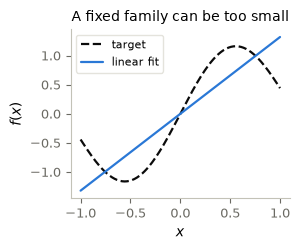

In [30]:
def target(x):
    return np.sin(3 * x) + 0.3 * x

x = np.linspace(-1, 1, 160)
y = target(x)

A = np.column_stack([np.ones_like(x), x])
intercept, slope = np.linalg.lstsq(A, y, rcond=None)[0] # Linear least squares fit

fig, ax = P.panels(size=(3.1, 2.6))
ax.plot(x, y, '--', color=P.INK, label='target')
ax.plot(x, intercept + slope * x, label='linear fit')
P.label(ax, '$x$', '$f(x)$', title='A fixed family can be too small')
plt.show()

## 1. Universal Approximation Theorems: A short history

An **ansatz** is a choice of model family. A common recipe is

$$f(x)=\sum_{j=1}^{m} c_j\,\varphi_j(x).$$

The history is partly a search for useful building blocks $\varphi_j$. The last two columns give the pieces and the sums that Section 2 plots:

| When | Idea | Building block $\varphi_j(x)$ | Model $f(x)$ |
|---|---|---|---|
| 1885 — [Weierstrass](https://history-of-approximation-theory.com/fpapers/wei3.pdf) | Approximate continuous functions by polynomials | $x^{j}$, $\;j=0,\dots,m-1$ | $\displaystyle\sum_{j=0}^{m-1} c_j\,x^{j}$ |
| 1932 — [Wiener](https://doi.org/10.2307/1968102) | Translate copies of one function | $\varphi(x-t_j)$, $\;\varphi(x)=e^{-x^2/(2h^2)}$ | $\displaystyle\sum_{j=1}^{m} c_j\,\varphi(x-t_j)$ |
| 1943 — [Courant](https://doi.org/10.1090/S0002-9904-1943-07818-4) | Use simple functions on small mesh cells | $\max\!\left(0,\,1-\dfrac{\lvert x-x_j\rvert}{h}\right)$ | $\displaystyle\sum_{j=1}^{m} c_j\,\varphi_j(x)$ |
| 1989 — [Cybenko](https://doi.org/10.1007/BF02551274) | Combine neurons in one hidden layer | $\sigma(a_jx+b_j)$, $\;\sigma(t)=\dfrac{1}{1+e^{-t}}$ | $\displaystyle c_0+\sum_{j=1}^{m-1} c_j\,\sigma(a_jx+b_j)$ |

**Density** means that, for every continuous target $g$ on our interval and every tolerance $\varepsilon>0$, some sufficiently large model satisfies

$$\max_{x\in[-1,1]}|g(x)-f(x)|<\varepsilon.$$

This describes uniform approximation on an interval. Wiener's original theorem uses a different distance, $L^1$ on the whole real line; we will keep that distinction when we reach it.

**Existence is the starting point.** A density theorem does not tell us how many pieces we need or how to find their parameters.

In [31]:
def polynomials(x, m):
    return x[:, None] ** np.arange(m)

def gaussian_translates(x, m, width=0.4):
    centers = np.linspace(-1.5, 1.5, m)
    return np.exp(-0.5 * ((x[:, None] - centers) / width) ** 2)

def hats(x, m):
    nodes = np.linspace(-1, 1, m)
    spacing = nodes[1] - nodes[0]
    return np.maximum(0, 1 - np.abs(x[:, None] - nodes) / spacing)

def sigmoid_neurons(x, m, slope=8):
    centers = np.linspace(-1, 1, m - 1)
    neurons = 1 / (1 + np.exp(-slope * (x[:, None] - centers)))
    return np.column_stack([np.ones_like(x), neurons])

families = {
    'Polynomials': polynomials,
    'Gaussian translates': gaussian_translates,
    'Hat functions': hats,
    'Sigmoid neurons': sigmoid_neurons,
}

### Comparison of the four families

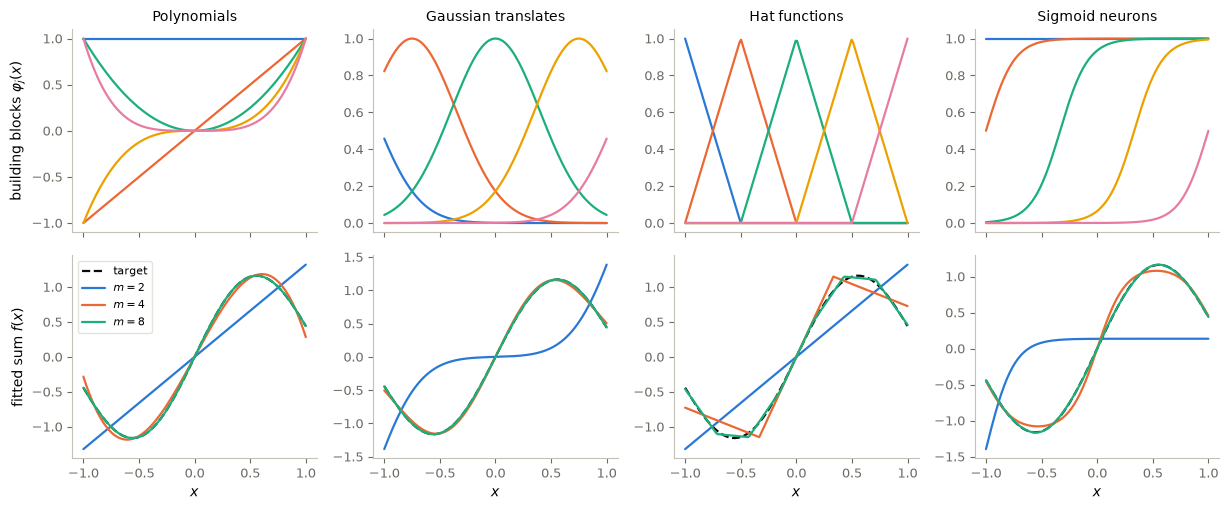

In [32]:
fig, axes = P.panels(4, 2, size=(3.1, 2.6), sharex=True)
for (name, features), ax_basis, ax_fit in zip(families.items(), *axes):
    ax_basis.plot(x, features(x, 5))
    ax_fit.plot(x, y, '--', color=P.INK, label='target')
    for m in (2, 4, 8):
        coefficients = np.linalg.lstsq(features(x, m), y, rcond=None)[0]
        ax_fit.plot(x, features(x, m) @ coefficients, label=f'$m={m}$')
    P.label(ax_basis, title=name)
    P.label(ax_fit, '$x$', legend=ax_fit is axes[1, 0])
axes[0, 0].set_ylabel(r'building blocks $\varphi_j(x)$')
axes[1, 0].set_ylabel('fitted sum $f(x)$')
plt.show()


### From approximation to optimization

All four families built a curve by adding simple pieces. Once those pieces were fixed, one least-squares call found the output coefficients.

For a network, we also want to move and reshape the pieces. Write all parameters as $w$ and minimize the training loss

$$F(w)=\frac1N\sum_{i=1}^N\big(f(x_i;w)-y_i\big)^2.$$

**Approximation asks whether good parameters exist. Optimization tries to find them.** The next sections isolate the choices that matter in that search.

## 3. Gradient descent: direction and step size

**Idea.** A local slope suggests a direction; a step size controls the movement.

Assume $F$ is differentiable and we want to minimize it, $\min_{w\in\mathbb R^d}F(w)$. The first-order Taylor expansion

$$F(w)=F(w_k)+\langle\nabla F(w_k),\,w-w_k\rangle+o(\|w-w_k\|)$$

gives a *linear* model of $F$ near $w_k$. When the gradient is nonzero, this model is unbounded below, so minimizing it alone makes no sense. Adding a quadratic penalty for long steps gives a model with a unique minimizer:

$$
\begin{align*}
w_{k+1}&=\arg\min_{u\in\mathbb R^d}\Big\{F(w_k)+\langle\nabla F(w_k),\,u-w_k\rangle+\tfrac1{2\eta}\|u-w_k\|^2\Big\}\\
&=w_k-\eta\nabla F(w_k).
\end{align*}
$$

The gradient picks the direction, the **learning rate** $\eta>0$ picks how far. In a non-convex problem the same iteration can also approach saddle points and local minima.

> Gradient descent is the explicit Euler discretization, with step size $\eta$, of the continuous-time gradient flow $\dot w=-\nabla F(w)$.

In [33]:
def quadratic(w):
    return 0.5 * (w[..., 0] ** 2 + 20 * w[..., 1] ** 2) # F(w) = 1/2 * (w_1^2 + 20 w_2^2)

def grad_quadratic(w):
    return np.array([1.0, 20.0]) * w

def gradient_descent(gradient, start, eta, steps=30):
    w = np.array(start, dtype=float)
    path = [w.copy()]
    for _ in range(steps):
        w = w - eta * gradient(w)
        path.append(w.copy())
    return np.array(path)

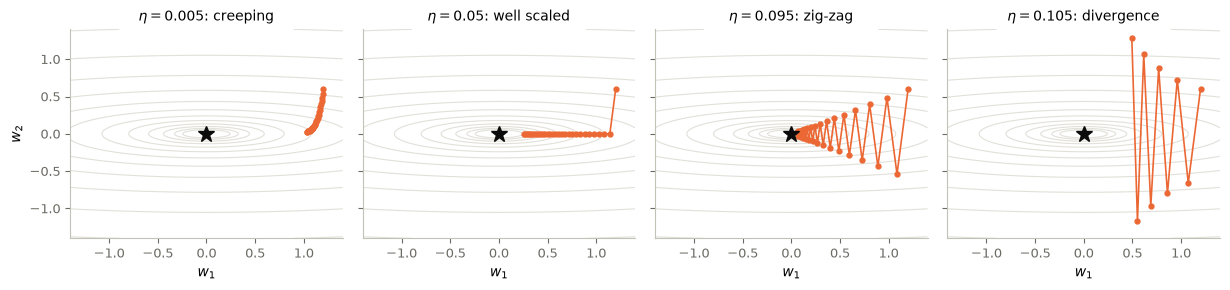

In [34]:
grid = np.linspace(-1.4, 1.4, 250)
W1, W2 = np.meshgrid(grid, grid)
Z = quadratic(np.stack([W1, W2], axis=-1))
start = [1.2, 0.6]
step_sizes = [0.005, 0.05, 0.095, 0.105]
notes = ['creeping', 'well scaled', 'zig-zag', 'divergence']

fig, axes = P.panels(4, size=(3.1, 3), sharex=True, sharey=True)
for ax, eta, note in zip(axes, step_sizes, notes):
    steps = 8 if eta > 0.1 else 30
    path = gradient_descent(grad_quadratic, start, eta, steps)
    P.contour_path(ax, W1, W2, Z, path=path, optimum=(0, 0),
                   marker='-o', levels=np.geomspace(0.03, 20, 12),
                   xlabel='$w_1$', xlim=(-1.4, 1.4), ylim=(-1.4, 1.4),
                   title=rf'$\eta={eta}$: {note}')
axes[0].set_ylabel('$w_2$')
plt.show()

## 4. Why it converges: smoothness and the descent lemma

**Idea.** Bound the curvature to control how much the objective can change after a step.

> **Assumption ($L$-smoothness).** $F$ is differentiable and $\nabla F$ is $L$-Lipschitz:
>
> $$\|\nabla F(u)-\nabla F(v)\|\le L\,\|u-v\|\qquad\forall\,u,v,$$
>
> equivalently $-LI\preceq\nabla^2F(w)\preceq LI$ when $F$ is twice differentiable. Curvature is bounded, so the gradient measured at $w$ stays informative over steps controlled by the curvature scale $L$ — and nothing forces $F$ to be convex.

> **Lemma (descent lemma).**
>
> $$F(v)\le F(u)+\langle\nabla F(u),\,v-u\rangle+\frac L2\|v-u\|^2\qquad\forall\,u,v.$$

*Optional proof.* Write the increment along the segment $u+t(v-u)$, $t\in[0,1]$, with the fundamental theorem of calculus:

$$F(v)-F(u)-\langle\nabla F(u),v-u\rangle=\int_0^1\big\langle\nabla F\big(u+t(v-u)\big)-\nabla F(u),\ v-u\big\rangle\,dt.$$

Bound the integrand with Cauchy–Schwarz and then with the Lipschitz assumption, $\|\nabla F(u+t(v-u))-\nabla F(u)\|\le Lt\|v-u\|$:

$$\le\int_0^1Lt\,\|v-u\|^2\,dt=\frac L2\|v-u\|^2.\qquad\blacksquare$$

This is the whole mechanism in one line: **the quadratic model we minimized to derive gradient descent is a global upper bound on $F$ as soon as $1/\eta\ge L$.** Minimizing an upper bound that touches $F$ at $w_k$ cannot increase $F$.

> **Theorem 1 (decay of the gradient).** Let $F$ be $L$-smooth and bounded below by $F^\star$, and let $0<\eta\le1/L$. Then gradient descent satisfies
>
> $$F(w_{k+1})\le F(w_k)-\frac\eta2\|\nabla F(w_k)\|^2\qquad\text{and}\qquad\min_{0\le k<K}\|\nabla F(w_k)\|^2\le\frac{2\big(F(w_0)-F^\star\big)}{\eta K}.$$

*Optional proof.* Apply the lemma with $u=w_k$ and $v=w_{k+1}=w_k-\eta\nabla F(w_k)$:

$$F(w_{k+1})\le F(w_k)-\eta\|\nabla F(w_k)\|^2+\frac{L\eta^2}2\|\nabla F(w_k)\|^2=F(w_k)-\eta\Big(1-\frac{L\eta}2\Big)\|\nabla F(w_k)\|^2,$$

and $\eta L\le1$ gives $1-L\eta/2\ge1/2$, which is the first claim. Summing it for $k=0,\dots,K-1$ telescopes:

$$\frac\eta2\sum_{k=0}^{K-1}\|\nabla F(w_k)\|^2\le F(w_0)-F(w_K)\le F(w_0)-F^\star,$$

and the minimum of $K$ terms is at most their average. $\blacksquare$

> **Theorem 2 (convex case).** If in addition $F$ is convex with a minimizer $w^\star$ and $0<\eta\le1/L$, then
>
> $$F(w_K)-F^\star\le\frac{\|w_0-w^\star\|^2}{2\eta K}.$$

*Optional proof.* Expand the distance to $w^\star$ and use convexity, $\langle\nabla F(w_k),w_k-w^\star\rangle\ge F(w_k)-F^\star$:

$$\|w_{k+1}-w^\star\|^2=\|w_k-w^\star\|^2-2\eta\langle\nabla F(w_k),w_k-w^\star\rangle+\eta^2\|\nabla F(w_k)\|^2\le\|w_k-w^\star\|^2-2\eta\big(F(w_k)-F^\star\big)+\eta^2\|\nabla F(w_k)\|^2.$$

Theorem 1 bounds the last term by the achieved decrease, $\eta^2\|\nabla F(w_k)\|^2\le2\eta\,(F(w_k)-F(w_{k+1}))$, so

$$\|w_{k+1}-w^\star\|^2\le\|w_k-w^\star\|^2-2\eta\big(F(w_{k+1})-F^\star\big).$$

Summing over $k<K$ telescopes the left side, and $F(w_k)$ is non-increasing, so the $K$ remaining terms are all at least $F(w_K)-F^\star$:

$$2\eta K\big(F(w_K)-F^\star\big)\le\sum_{k=0}^{K-1}2\eta\big(F(w_{k+1})-F^\star\big)\le\|w_0-w^\star\|^2-\|w_K-w^\star\|^2\le\|w_0-w^\star\|^2.\qquad\blacksquare$$

| Assumptions | Measure | Rate | Iterations to reach the stated tolerance |
|---|---|---|---|
| $L$-smooth, bounded below | $\min_k\lVert\nabla F(w_k)\rVert^2$ | $O(1/K)$ | $O(\varepsilon^{-2})$ for $\lVert\nabla F\rVert\le\varepsilon$ |
| $L$-smooth and convex, with a minimizer | $F(w_K)-F^\star$ | $O(1/K)$ | $O(\varepsilon^{-1})$ for $F(w_K)-F^\star\le\varepsilon$ |

A small gradient can indicate a local minimum or a saddle point in a non-convex problem.

## 5. Momentum: carry the previous step

**Idea.** Carry some of the previous step into the next update.

Gradient descent uses only the current gradient. In a narrow valley, it can zigzag across the steep sides while making slow progress along the valley. [Polyak's heavy-ball method (1964)](https://www.mathnet.ru/eng/zvmmf7713) gives the iterate a **velocity** that carries part of each step into the next:

$$v_{k+1}=\beta v_k-\eta\nabla F(w_k),\qquad w_{k+1}=w_k+v_{k+1}.$$

Here $\eta$ is the step size, and $\beta$ controls how much of the previous velocity is retained. When $\beta=0$, the method reduces to gradient descent.

The two methods have different continuous-time limits. Gradient descent approaches the first-order flow when time advances by $\eta$ per step. Heavy ball approaches the second-order flow when time advances by $\sqrt\eta$ per step and $\beta=1-a\sqrt\eta$:

$$\begin{align*}&\dot w=-\nabla F(w), \tag{gradient descent}\\ &\ddot w+a\,\dot w+\nabla F(w)=0. \tag{heavy ball}\end{align*}$$

The second equation describes a ball rolling on the loss surface with friction $a$: inertia lets it keep moving along the valley floor, and it can also overshoot.

Add one variable to our loop, then compare the paths and losses of the two methods using the same learning rate.

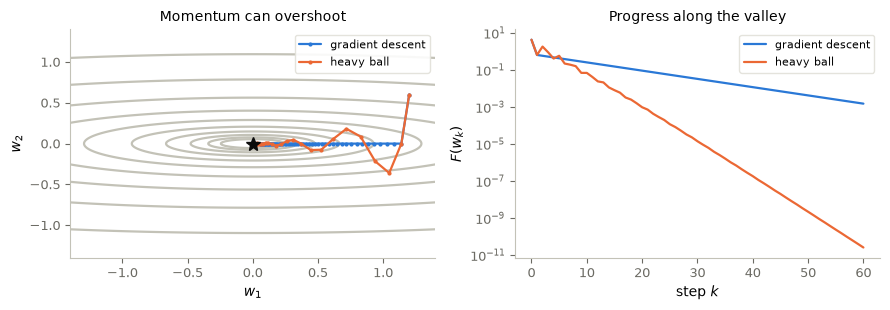

In [35]:
def heavy_ball(gradient, start, eta, beta=0.6, steps=60):
    w = np.array(start, dtype=float)
    velocity = np.zeros_like(w)
    path = [w.copy()]
    for _ in range(steps):
        velocity = beta * velocity - eta * gradient(w)
        w = w + velocity
        path.append(w.copy())
    return np.array(path)

momentum_paths = {
    'gradient descent': gradient_descent(grad_quadratic, start, 0.05, steps=60),
    'heavy ball': heavy_ball(grad_quadratic, start, 0.05),
}

fig, (ax_path, ax_loss) = P.panels(2, size=(4.5, 3.2))
ax_path.contour(W1, W2, Z, levels=np.geomspace(0.03, 12, 10), colors=P.RULE)
for name, path in momentum_paths.items():
    ax_path.plot(*path.T, '-o', ms=2, label=name)
    ax_loss.semilogy(quadratic(path), label=name)
ax_path.plot(0, 0, '*', color=P.INK, ms=10)
P.label(ax_path, '$w_1$', '$w_2$', title='Momentum can overshoot')
P.label(ax_loss, 'step $k$', '$F(w_k)$', title='Progress along the valley')
plt.show()

### 5.1 The same optimizers on three different problems

Other widely used first-order methods refine this idea. **Nesterov momentum** evaluates the gradient at a look-ahead point; **RMSProp** and **Adam** use running averages of gradients and their squares to scale the updates coordinate by coordinate. We use PyTorch's implementations so that the training loop stays the same. [Nesterov (1983)](https://www.mathnet.ru/eng/dan46009), [Hinton (2012)](https://www.cs.toronto.edu/~hinton/coursera/lecture6/lec6.pdf), [Kingma and Ba (2014)](https://arxiv.org/abs/1412.6980)

Compare an elongated quadratic with curvatures from $1$ to $100$, the curved Rosenbrock valley, and a small network fitting our target. Every method starts from the same parameters within each problem. Learning rates are chosen separately for Adam, so these curves illustrate behavior rather than establish an optimizer ranking.

In [36]:
curvatures = torch.logspace(0, 2, 50)
inputs = torch.tensor(x, dtype=torch.float32)[:, None]
targets = torch.tensor(y, dtype=torch.float32)[:, None]

def make_quadratic():
    w = torch.ones(50, requires_grad=True)
    return [w], lambda: 0.5 * (curvatures * w ** 2).sum()

def make_rosenbrock():
    w = torch.tensor([-1.2, 1.0], requires_grad=True)
    return [w], lambda: (1 - w[0]) ** 2 + 100 * (w[1] - w[0] ** 2) ** 2

def make_network():
    torch.manual_seed(0)
    return nn.Sequential(nn.Linear(1, 16), nn.Tanh(), nn.Linear(16, 1))

def make_network_problem():
    net = make_network()
    return list(net.parameters()), lambda: ((net(inputs) - targets) ** 2).mean()

The three essential training operations are `zero_grad()` (clear old derivatives), `backward()` (compute new derivatives), and `step()` (update parameters). In this comparison each step uses the full objective.

In [37]:
methods = {
    'gradient descent': lambda p, lr: torch.optim.SGD(p, lr=lr),
    'heavy ball': lambda p, lr: torch.optim.SGD(p, lr=lr, momentum=0.9),
    'Nesterov': lambda p, lr: torch.optim.SGD(p, lr=lr, momentum=0.9, nesterov=True),
    'Adam': lambda p, lr: torch.optim.Adam(p, lr=lr),
}

def optimize(setup, method, lr, steps=300):
    parameters, objective = setup()
    optimizer = methods[method](parameters, lr)
    losses = [objective().item()]
    for _ in range(steps):
        optimizer.zero_grad()
        loss = objective()
        loss.backward()
        optimizer.step()
        losses.append(objective().item())
    return losses

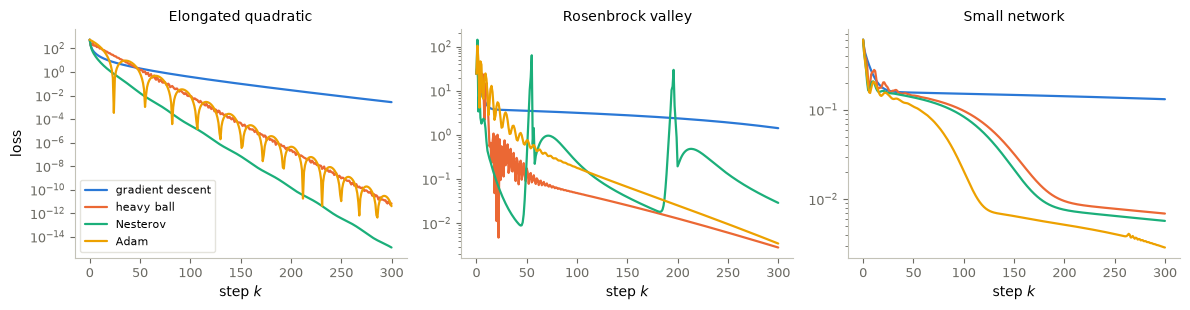

In [38]:
# Each row gives: title, problem, GD/momentum learning rate, Adam learning rate.
problems = [
    ('Elongated quadratic', make_quadratic, 0.01, 0.05),
    ('Rosenbrock valley', make_rosenbrock, 0.002, 0.5),
    ('Small network', make_network_problem, 0.05, 0.03),
]

optimizer_losses = {}
fig, axes = P.panels(3, size=(4, 3.2))
for ax, (title, setup, lr, adam_lr) in zip(axes, problems):
    for method in methods:
        rate = adam_lr if method == 'Adam' else lr
        losses = optimize(setup, method, rate)
        optimizer_losses[title, method] = losses
        ax.semilogy(losses, label=method)
    P.label(ax, 'step $k$', title=title, legend=ax is axes[0])
axes[0].set_ylabel('loss')
plt.show()

**Look for:** smooth decreases, oscillations, and plateaus. A method that works well in a straight valley can behave differently when the valley bends. Changing the learning rate can change the comparison.

## 6. Non-convex problems and the stochastic gradient

**Idea.** Noise can help leave a local basin, but it also limits accuracy.

Many machine learning objectives are non-convex. Under its assumptions, Theorem 1 guarantees small gradients, rather than convergence to a global minimum or to a particular point. The starting point matters, and noise can sometimes help the iterates leave a local basin. Perturb the gradient flow of Section 3 with white noise,

$$dw_t=-\nabla F(w_t)\,dt+\sigma\,dB_t,$$

with $B$ a $d$-dimensional Brownian motion and $\sigma>0$ the noise level. The Euler–Maruyama discretization with step $\eta$ is the algorithm we actually run,

$$w_{k+1}=w_k-\eta\,\nabla F(w_k)+\sigma\sqrt\eta\,\xi_k,\qquad\xi_k\sim\mathcal N(0,I_d)\quad\text{i.i.d.},$$


In [39]:
def well(w):
    return (w ** 2 - 1) ** 2 + 0.3 * w

def grad_well(w):
    return 4 * w * (w ** 2 - 1) + 0.3

w_grid = np.linspace(-2, 2, 2001)
near_zero = np.abs(w_grid) < 0.5
barrier = w_grid[near_zero][np.argmax(well(w_grid[near_zero]))]  # the local maximum between the wells
w_star = w_grid[np.argmin(well(w_grid))]                          # the global minimizer

def langevin_1d(sigma, start, eta=0.05, steps=400, seed=0):
    rng = np.random.default_rng(seed)
    w = start
    path = [w]
    for _ in range(steps):
        w = w - eta * grad_well(w) + sigma * np.sqrt(eta) * rng.standard_normal()
        path.append(w)
    return np.array(path)

w_0 = 1.5  # both runs start on the right slope
runs_1d = {
    'gradient descent': langevin_1d(sigma=0.0, start=w_0, eta=0.005),  # a small step, to watch it roll down
    'noisy gradient': langevin_1d(sigma=0.7, start=w_0),
}

In [40]:
descent, noisy = runs_1d.values()
fig, (ax_land, ax_pos) = P.panels(2, figsize=(8.5, 3.2), dpi=80)
ax_land.plot(w_grid, well(w_grid), color=P.INK, lw=1)
ax_land.plot(w_star, well(w_star), '*', color=P.INK, ms=12)
P.label(ax_land, '$w$', '$F(w)$', xlim=(-2, 2), ylim=(-0.6, 3))
ax_pos.axhline(barrier, color=P.INK, ls='--', lw=1)
P.label(ax_pos, 'iteration $k$', '$w_k$', xlim=(0, len(noisy) - 1), ylim=(-1.9, 1.9))

artists = []
for (name, path), color in zip(runs_1d.items(), P.CYCLE):
    dot, = ax_land.plot([], [], 'o', color=color, ms=8, label=name)
    trace, = ax_pos.plot([], [], color=color, lw=1)
    artists.append((path, dot, trace))
ax_land.legend(loc='upper center')

stride = 8
def update(i):
    k = stride * i
    for path, dot, trace in artists:
        dot.set_data([path[k]], [well(path[k])])
        trace.set_data(np.arange(k + 1), path[:k + 1])

P.animate(fig, update, (len(noisy) - 1) // stride + 1, interval=150)

**Read the paths.** Deterministic descent stays in its starting basin. Constant noise keeps the iterates moving between basins, as in the one-dimensional experiment; annealing lets them explore first and settle afterwards. Try another seed to see why one successful trajectory is not a guarantee.

## 7. Train the network: mini-batch gradients


The full loss averages over all $N$ samples. A **mini-batch** $B_k$ replaces that average by a smaller one:

$$g_k=\frac1{|B_k|}\sum_{i\in B_k}\nabla_w\big(f(x_i;w_k)-y_i\big)^2,\qquad w_{k+1}=w_k-\eta g_k.$$

Here the randomness comes from choosing data, and it enters multiplied by $\eta$: this is the stochastic gradient of Section 6, not the Langevin step with its $\sigma\sqrt\eta$ noise. They are different algorithms with the same flavor, a cheap step plus a random perturbation.

An **epoch** is one pass through the data. Compare full-batch descent with batches of 16, using the same initial network, learning rate, and number of epochs. We record the full training loss after each epoch so both curves measure the same quantity.

In [41]:
def train(batch_size, epochs=200, lr=0.05):
    net = make_network()  # identical initial weights for both runs
    optimizer = torch.optim.SGD(net.parameters(), lr=lr)
    generator = torch.Generator().manual_seed(1)
    with torch.no_grad():
        losses = [((net(inputs) - targets) ** 2).mean().item()]
    for _ in range(epochs):
        order = torch.randperm(len(inputs), generator=generator)
        for batch in order.split(batch_size):
            optimizer.zero_grad()
            loss = ((net(inputs[batch]) - targets[batch]) ** 2).mean()
            loss.backward()
            optimizer.step()
        with torch.no_grad():
            losses.append(((net(inputs) - targets) ** 2).mean().item())
    return net, losses

training_runs = {
    'full batch (160)': train(batch_size=160),
    'mini-batch (16)': train(batch_size=16),
}

full batch (160): final training MSE = 0.1424, max grid error = 0.9286
mini-batch (16): final training MSE = 0.005684, max grid error = 0.2603


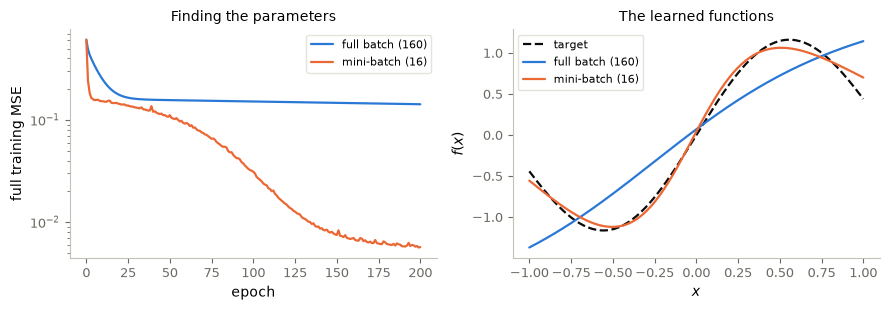

In [42]:
fig, (ax_loss, ax_fit) = P.panels(2, size=(4.5, 3.2))
ax_fit.plot(x, y, '--', color=P.INK, label='target')
for name, (net, losses) in training_runs.items():
    ax_loss.semilogy(losses, label=name)
    with torch.no_grad():
        prediction = net(inputs).numpy().ravel()
    ax_fit.plot(x, prediction, label=name)
    grid_error = np.max(np.abs(prediction - y))
    print(f'{name}: final training MSE = {losses[-1]:.4g}, max grid error = {grid_error:.4g}')
P.label(ax_loss, 'epoch', 'full training MSE', title='Finding the parameters')
P.label(ax_fit, '$x$', '$f(x)$', title='The learned functions')
plt.show()

## 8. Everything at once: classifying handwritten digits

So far the target was one curve on $[-1,1]$ and the network had 49 parameters. The same ingredients scale to a real task. [MNIST](https://doi.org/10.1109/5.726791) contains 60000 training and 10000 test images of handwritten digits, each $28\times28$ grey pixels, so an input is a vector $x\in\mathbb R^{784}$ and its label is a class $y\in\{0,\dots,9\}$.

**Model.** One hidden layer of 128 ReLU neurons: Cybenko's family from Section 1, now with vector inputs and ten outputs,

$$f(x;w)=W_2\,\sigma(W_1x+b_1)+b_2\in\mathbb R^{10},\qquad\sigma(t)=\max(0,t),$$

with $w=(W_1,b_1,W_2,b_2)$. The softmax turns the ten outputs into class probabilities, $p_j(x;w)=e^{f_j(x;w)}\big/\sum_{k}e^{f_k(x;w)}$, and the prediction is the class with the largest probability.

**Loss.** For classification, the squared error is replaced by the **cross-entropy**, the negative log-probability of the correct class:

$$F(w)=\frac1N\sum_{i=1}^N-\log p_{y_i}(x_i;w).$$


In [46]:
import gzip, pathlib, urllib.request

def load_mnist(split):
    """Images as floats in [0, 1] with shape (N, 784) and labels as integers 0-9."""
    base = 'https://storage.googleapis.com/cvdf-datasets/mnist/' + ('train' if split == 'train' else 't10k')
    arrays = {}
    for kind, offset in (('images', 16), ('labels', 8)):
        path = pathlib.Path('data') / f'mnist-{split}-{kind}.gz'  # downloaded once, shared with notebook 17
        if not path.exists():
            path.parent.mkdir(exist_ok=True)
            urllib.request.urlretrieve(f'{base}-{kind}-idx{3 if kind == "images" else 1}-ubyte.gz', path)
        arrays[kind] = np.frombuffer(gzip.decompress(path.read_bytes()), dtype=np.uint8, offset=offset)
    images = torch.tensor(arrays['images'].reshape(-1, 784).copy(), dtype=torch.float32) / 255
    labels = torch.tensor(arrays['labels'].copy(), dtype=torch.int64)
    return images, labels

train_images, train_labels = load_mnist('train')
test_images, test_labels = load_mnist('test')
print(f'{len(train_images)} training and {len(test_images)} test images of {train_images.shape[1]} pixels')

60000 training and 10000 test images of 784 pixels


In [47]:
def make_classifier(width=128):
    torch.manual_seed(0)
    return nn.Sequential(nn.Linear(784, width), nn.ReLU(), nn.Linear(width, 10))

def accuracy(net, images, labels):
    with torch.no_grad():
        return (net(images).argmax(1) == labels).float().mean().item()

def train_mnist(net, epochs=5, batch_size=64, lr=1e-3):
    optimizer = torch.optim.Adam(net.parameters(), lr=lr)
    cross_entropy = nn.CrossEntropyLoss()  # softmax and -log p_y in one numerically stable call
    generator = torch.Generator().manual_seed(1)
    batch_losses, test_accuracy = [], [accuracy(net, test_images, test_labels)]
    for epoch in range(epochs):
        order = torch.randperm(len(train_images), generator=generator)
        for batch in order.split(batch_size):
            optimizer.zero_grad()
            loss = cross_entropy(net(train_images[batch]), train_labels[batch])
            loss.backward()
            optimizer.step()
            batch_losses.append(loss.item())
        test_accuracy.append(accuracy(net, test_images, test_labels))
        print(f'epoch {epoch + 1}: test accuracy = {100 * test_accuracy[-1]:.2f}%')
    return net, np.array(batch_losses), np.array(test_accuracy)

net = make_classifier()
print(f'{sum(p.numel() for p in net.parameters())} parameters')
net, batch_losses, test_accuracy = train_mnist(net)

101770 parameters
epoch 1: test accuracy = 94.29%
epoch 2: test accuracy = 96.23%
epoch 3: test accuracy = 96.90%
epoch 4: test accuracy = 97.53%
epoch 5: test accuracy = 97.59%


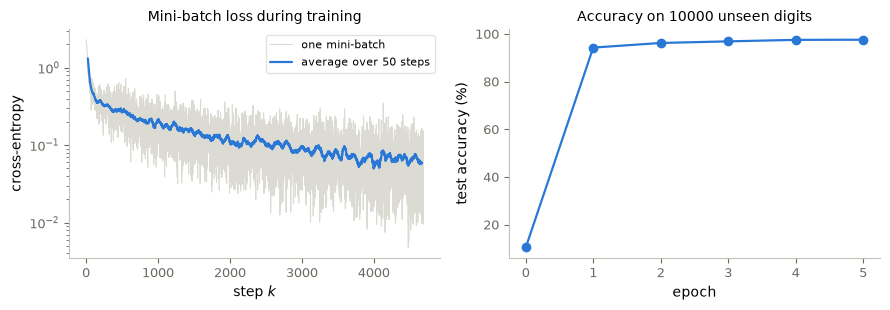

In [48]:
window = 50
average = P.smooth(batch_losses, window)

fig, (ax_loss, ax_acc) = P.panels(2, size=(4.5, 3.2))
ax_loss.semilogy(batch_losses, color=P.GHOST, lw=0.8, label='one mini-batch')
ax_loss.semilogy(np.arange(len(average)) + window // 2, average, label=f'average over {window} steps')
P.label(ax_loss, 'step $k$', 'cross-entropy', title='Mini-batch loss during training')
ax_acc.plot(100 * test_accuracy, '-o')
P.label(ax_acc, 'epoch', 'test accuracy (%)', title='Accuracy on 10000 unseen digits',
        xticks=range(len(test_accuracy)))
plt.show()

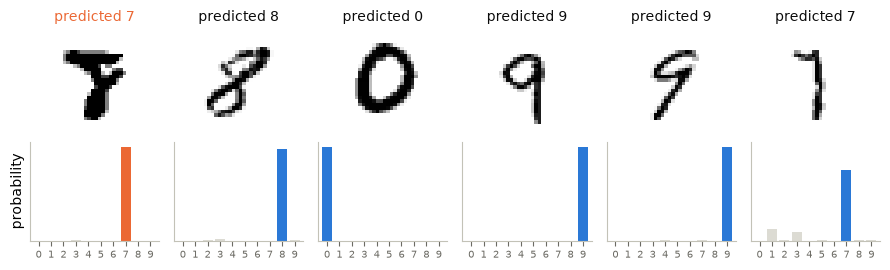

In [49]:
generator = torch.Generator().manual_seed(4)
sample = torch.randint(len(test_images), (6,), generator=generator)  # six test images drawn at random
with torch.no_grad():
    probabilities = torch.softmax(net(test_images[sample]), dim=1)
predicted = probabilities.argmax(1)

fig, (ax_images, ax_bars) = P.panels(len(sample), 2, size=(1.5, 1.4), sharey='row')
for k, (ax_image, ax_bar, i) in enumerate(zip(ax_images, ax_bars, sample)):
    truth, prediction = test_labels[i].item(), predicted[k].item()
    ax_image.imshow(test_images[i].reshape(28, 28), cmap='gray_r', vmin=0, vmax=1)
    P.label(ax_image, title=f'predicted {prediction}', off=True)
    ax_image.title.set_color(P.INK if prediction == truth else P.ORANGE)
    colors = [P.BLUE if c == truth else P.ORANGE if c == prediction else P.GHOST for c in range(10)]
    ax_bar.bar(range(10), probabilities[k], color=colors)
    P.label(ax_bar, xlim=(-0.7, 9.7), ylim=(0, 1.05), xticks=range(10), yticks=[0, 1] if k == 0 else [])
    ax_bar.tick_params(axis='x', labelsize=7)
ax_bars[0].set_ylabel('probability')
plt.show()

## Key takeaways

- **Representation:** different building blocks can describe the same target; density is an existence statement that says nothing about how many pieces are needed or how to find their parameters.
- **Gradient descent** minimizes a local linear model plus a quadratic penalty for long steps. Smoothness controls the step size; convexity gives a bound on the objective gap.
- **Momentum** carries information from previous steps and can accelerate some problems, at the risk of overshooting.
- **Noise** trades accuracy for exploration: the Gibbs measure of Appendix A concentrates on the deepest basin as $\sigma\to0$, but reaching it takes longer. Explicit Brownian noise and mini-batch gradient noise are different constructions with the same trade-off.
- **In practice** the pieces combine: a one-hidden-layer network with ten outputs, the cross-entropy loss, mini-batch gradients, and Adam classify handwritten digits with about 97% test accuracy after a few passes through the data.

## Exercises

1. **Representation.** Change `target` to `np.abs(x)` and rerun the four-family figure. Which families handle the corner well, and which need many features?
2. **Stable steps.** Try learning rates just below and just above $0.1$ on the quadratic. Explain the difference using the multiplier $1-20\eta$.
3. **Momentum.** Set `beta=0` in `heavy_ball` and compare it with gradient descent at the same step size. Then set the momentum coefficient to zero in the three-problem comparison: which method should it reproduce, and do the curves agree?
4. **Escape.** Change the seed, then $\sigma$, in `langevin_1d`. How does the time to leave the shallow well depend on $\sigma$? Compare with Kramers' law, $e^{2\Delta F/\sigma^2}$, using the barrier height read off the landscape.
5. **Annealing.** Change the random seed in `euler_maruyama`. Does the annealed run always find the deepest basin?
6. **Equilibrium.** In Appendix A, add $\sigma=0.3$ to `noise_levels`. Estimate from Kramers' law how long the copies need to cross the barrier, and check whether the run is long enough to see it.
7. **Batches.** Train with batch sizes 1, 16, and 160. Compare equal epochs, then adjust the epochs to compare equal update counts.
8. **Digits.** In `train_mnist`, replace Adam by `torch.optim.SGD` with the same learning rate, then add `momentum=0.9`. Compare the loss curves after one epoch. Then set the hidden width to 16 and to 512: does the test accuracy follow the training loss?

For more detail: [optimization methods](11_optimization.ipynb) and [shallow networks](12_shallow_networks.ipynb).

## Appendix A. The Gibbs measure

Section 6 claimed that the noisy gradient flow forgets its starting point and settles on the deepest basin. Here is the statement, its proof, and a numerical check.

> **Theorem 3 (Gibbs measure).** Let $F$ be $C^2$ with global minimum value $F^\star$ and $\int e^{-F(w)}\,dw<\infty$, and let $0<\sigma\le1$. Then
>
> 1. the Gibbs density $\pi_\sigma(w)=Z_\sigma^{-1}e^{-2F(w)/\sigma^2}$ is stationary for the noisy gradient flow: if $w_0\sim\pi_\sigma$, then $w_t\sim\pi_\sigma$ for all $t\ge0$;
> 2. $\pi_\sigma$ concentrates on near-optimal points: for every $\varepsilon>0$,
>
> $$\pi_\sigma\big(\{w:F(w)>F^\star+\varepsilon\}\big)\;\le\;C_\varepsilon\,e^{-\varepsilon/(2\sigma^2)}\;\xrightarrow[\sigma\to0]{}\;0.$$

*Optional proof.* (1) The density $p_t$ of $w_t$ solves the Fokker–Planck equation

$$\partial_tp=\nabla\cdot\Big(p\,\nabla F+\frac{\sigma^2}2\nabla p\Big).$$

For $p=\pi_\sigma$ we have $\nabla\pi_\sigma=-\frac2{\sigma^2}\pi_\sigma\nabla F$, so the flux in brackets vanishes and $\partial_tp=0$.

(2) Write $g=F-F^\star\ge0$ and $A=\{g\le\varepsilon/4\}$, which has positive volume $|A|$ because $g$ is continuous and vanishes at a minimizer. Since $\sigma\le1$, on $\{g>\varepsilon\}$ we have $e^{-2g/\sigma^2}=e^{-g/\sigma^2}e^{-g/\sigma^2}\le e^{-\varepsilon/\sigma^2}e^{-g}$, while on $A$ we have $e^{-2g/\sigma^2}\ge e^{-\varepsilon/(2\sigma^2)}$. Hence

$$\pi_\sigma(g>\varepsilon)\le\frac{\int_{\{g>\varepsilon\}}e^{-2g/\sigma^2}\,dw}{\int_Ae^{-2g/\sigma^2}\,dw}\le\frac{e^{-\varepsilon/\sigma^2}\int e^{-g}\,dw}{e^{-\varepsilon/(2\sigma^2)}\,|A|}=\underbrace{\frac{\int e^{-g}\,dw}{|A|}}_{C_\varepsilon}\,e^{-\varepsilon/(2\sigma^2)}.\qquad\blacksquare$$

So at equilibrium the deepest basin dominates, wherever the iterates started, but a fixed $\sigma>0$ keeps them spread around it. Small $\sigma$ sharpens $\pi_\sigma$ but slows the approach to equilibrium, which is Kramers' law from Section 6: the theorem describes the limit $t\to\infty$ and says nothing about how long the wait is.

Watch the theorem on the double well of Section 6. The middle panel draws $\pi_\sigma$ for three noise levels. On the right, 2000 copies of the noisy update all start in the shallow well, and we track how many have crossed into the deep well: each curve settles at the mass that $\pi_\sigma$ assigns to the deep well (dashed), and the smaller $\sigma$, the higher that mass and the longer the wait.

In [ ]:
def gibbs(sigma):
    density = np.exp(-2 * (well(w_grid) - well(w_grid).min()) / sigma ** 2)
    return density / np.trapezoid(density, w_grid)

def deep_well_mass(sigma):
    deep = w_grid < barrier
    return np.trapezoid(gibbs(sigma)[deep], w_grid[deep])

def deep_well_fractions(sigmas, chains=2000, eta=0.02, time=2000.0, seed=0):
    rng = np.random.default_rng(seed)
    sigmas = np.asarray(sigmas, dtype=float)[:, None]
    w = np.ones((len(sigmas), chains))  # every copy starts in the shallow well
    steps = int(time / eta)
    fractions = np.empty((steps, len(sigmas)))
    for k in range(steps):
        w = w - eta * grad_well(w) + sigmas * np.sqrt(eta) * rng.standard_normal(w.shape)
        fractions[k] = np.mean(w < barrier, axis=1)
    return eta * np.arange(1, steps + 1), fractions

noise_levels = [1.2, 0.8, 0.5]
times, fractions = deep_well_fractions(noise_levels)

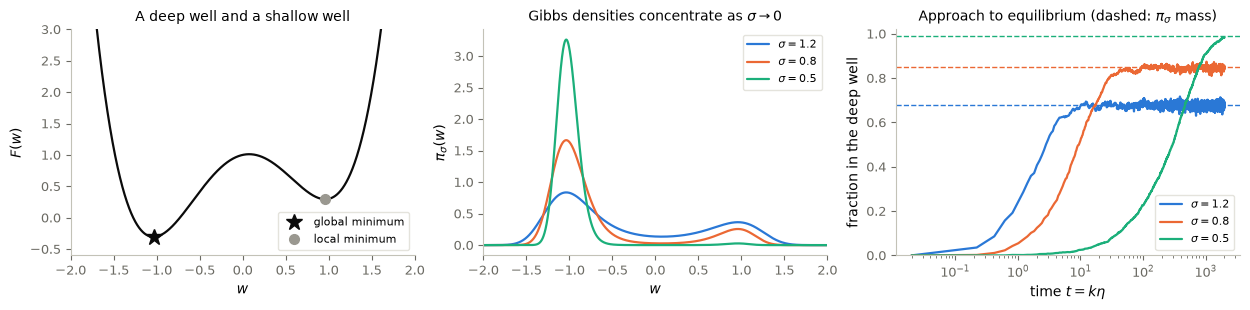

In [ ]:
shallow = w_grid[w_grid > barrier][np.argmin(well(w_grid[w_grid > barrier]))]

fig, (ax_land, ax_gibbs, ax_frac) = P.panels(3, size=(4.2, 3.2))
ax_land.plot(w_grid, well(w_grid), color=P.INK)
ax_land.plot(w_grid[np.argmin(well(w_grid))], well(w_grid).min(), '*', color=P.INK, ms=12,
             label='global minimum')
ax_land.plot(shallow, well(shallow), 'o', color=P.GREY, ms=7, label='local minimum')
P.label(ax_land, '$w$', '$F(w)$', title='A deep well and a shallow well', xlim=(-2, 2), ylim=(-0.6, 3))

for sigma, color in zip(noise_levels, P.CYCLE):
    ax_gibbs.plot(w_grid, gibbs(sigma), color=color, label=rf'$\sigma={sigma}$')
P.label(ax_gibbs, '$w$', r'$\pi_\sigma(w)$', title=r'Gibbs densities concentrate as $\sigma\to0$',
        xlim=(-2, 2))

for j, (sigma, color) in enumerate(zip(noise_levels, P.CYCLE)):
    ax_frac.semilogx(times[::10], fractions[::10, j], color=color, label=rf'$\sigma={sigma}$')
    ax_frac.axhline(deep_well_mass(sigma), color=color, ls='--', lw=1)
P.label(ax_frac, r'time $t=k\eta$', 'fraction in the deep well',
        title=r'Approach to equilibrium (dashed: $\pi_\sigma$ mass)', ylim=(0, 1.02))
plt.show()

**Read the right panel.** With $\sigma=1.2$ the copies equilibrate within a few time units, but a third of them still sit in the shallow well; with $\sigma=0.5$ nearly all end up in the deep well, after a wait a hundred times longer. This is the trade-off behind annealing in Section 6.

## Further reading

- K. Weierstrass, [*Über die analytische Darstellbarkeit sogenannter willkürlicher Functionen einer reellen Veränderlichen*](https://history-of-approximation-theory.com/fpapers/wei3.pdf), 1885 — polynomial approximation.
- N. Wiener, [*Tauberian theorems*](https://doi.org/10.2307/1968102), 1932 — density of translates.
- R. Courant, [*Variational methods for the solution of problems of equilibrium and vibrations*](https://doi.org/10.1090/S0002-9904-1943-07818-4), 1943 — approximation on meshes.
- G. Cybenko, [*Approximation by superpositions of a sigmoidal function*](https://doi.org/10.1007/BF02551274), 1989 — one hidden layer.
- J. Nocedal and S. J. Wright, [*Numerical Optimization*](https://doi.org/10.1007/978-0-387-40065-5), 2nd ed., Springer, 2006 — smoothness, descent, and convergence.
- B. T. Polyak, [*Some methods of speeding up the convergence of iteration methods*](https://www.mathnet.ru/eng/zvmmf7713), 1964 — heavy-ball momentum.
- Y. E. Nesterov, [*A method for solving the convex programming problem with convergence rate $O(1/k^2)$*](https://www.mathnet.ru/eng/dan46009), 1983.
- G. Hinton, [*Neural Networks for Machine Learning, Lecture 6*](https://www.cs.toronto.edu/~hinton/coursera/lecture6/lec6.pdf), 2012 — RMSProp.
- D. P. Kingma and J. Ba, [*Adam: a method for stochastic optimization*](https://arxiv.org/abs/1412.6980), 2014 — adaptive steps.
- S. Geman and C.-R. Hwang, [*Diffusions for global optimization*](https://doi.org/10.1137/0324060), SIAM J. Control Optim., 1986 — annealed Langevin dynamics.
- T.-S. Chiang, C.-R. Hwang and S.-J. Sheu, [*Diffusion for global optimization in $\mathbb R^n$*](https://doi.org/10.1137/0325042), SIAM J. Control Optim., 1987.
- Y. LeCun, L. Bottou, Y. Bengio and P. Haffner, [*Gradient-based learning applied to document recognition*](https://doi.org/10.1109/5.726791), Proc. IEEE, 1998 — the MNIST digits.
- L. Bottou, F. E. Curtis and J. Nocedal, [*Optimization methods for large-scale machine learning*](https://arxiv.org/abs/1606.04838), 2018 — gradient methods and stochastic training.